In [10]:
from openai import OpenAI
from pathlib import Path
import base64

HOST = "0.0.0.0"
PORT = 8000
MODEL = "internvl3_5_2b_medical"

client = OpenAI(
    api_key="EMPTY",
    base_url=f"http://{HOST}:{PORT}/v1",
)

print(client.models.list())

SyncPage[Model](data=[Model(id='internvl3_5_2b_medical', created=1781571129, object='model', owned_by='swift')], object='list')


In [ ]:
def image_to_data_url(image_path):
    path = Path(image_path)
    suffix = path.suffix.lower()

    if suffix == ".png":
        mime = "image/png"
    elif suffix in [".jpg", ".jpeg"]:
        mime = "image/jpeg"
    else:
        raise ValueError("Use a PNG/JPG/JPEG image.")

    b64 = base64.b64encode(path.read_bytes()).decode("utf-8")
    return f"data:{mime};base64,{b64}"

In [3]:
import glob
filepaths = glob.glob("/localstorage/cxr_data/internal_data/testing/images/**/*.png", recursive=True)

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

def show_image(path, figsize=(10, 12)):
    img = Image.open(path).convert("RGB")
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    plt.show()
    return img


In [ ]:
resp = client.chat.completions.create(
    model="internvl3_5_2b_medical",
    messages=[{
        "role": "user",
        "content": [
            {"type": "text", "text": "Describe the abnormalities in this image."},
            {"type": "image_url", "image_url": {"url": image_path}},   # raw path, server encodes it
        ],
    }],
    temperature=0,
    max_tokens=2048,
)

In [ ]:
/localstorage/cxr_data/internal_data/training/csvs/100k_testset_annotated_data.csv

In [4]:
import pandas as pd
df_test = pd.read_csv("/localstorage/cxr_data/internal_data/training/csvs/100k_testset_annotated_data.csv")

/tmp/ipykernel_1301961/478058896.py:2: DtypeWarning: Columns (30) have mixed types. Specify dtype option on import or set low_memory=False.
  df_test = pd.read_csv("/localstorage/cxr_data/internal_data/training/csvs/100k_testset_annotated_data.csv")


In [8]:
import os
subset_df = df_test[df_test["opacity"]==1]
subset_df

,filename,cardiomegaly,nodule,pneumothorax,mass,emphysema,normal,consolidation,peffusion,calcification,...,enlarged_hila,non ap/pa,pleural_thickening,homogenous,tubes,tracheal_shift,mediastinal_mass,reticular,copd_signs,user
0,dmims.1.2.392.200036.9107.307.15120.20171127.1...,0,0,0,0,0,0,1,0,0,...,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100
1,ca.50kstudies.unit6.8293c5249a95231a60f656cfc3...,0,1,0,0,0,0,0,0,0,...,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100
4,dmims.1.2.392.200036.9107.307.15120.20160908.1...,0,0,0,0,0,0,1,1,0,...,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100
5,ca.50kstudies.unit6.84e362bdc3b3d36c526c105727...,0,0,0,0,0,0,0,0,0,...,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100
6,krsnaa.1.2.392.200036.9125.4.0.487533052.19540...,0,0,0,0,0,0,0,1,0,...,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100.0,-100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107112,naw.1.3.51.0.7.4161893738.40394.60748.43211.62...,0,1,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,niharika
107115,max.dev4.182500589,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,niharika
107117,naw.1.3.51.0.7.13494638818.18219.40265.42249.4...,1,0,0,0,0,0,1,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,niharika
107121,medall.1.3.6.1.4.1.25403.52234588329.5752.2017...,1,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,niharika


In [ ]:

resp = client.chat.completions.create(
    model=MODEL,
    messages = [
            {"role": "system", "content": "You are a helpful medical assistant."},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}}
                ]
            }
        ]
        ,
    max_tokens=16000,
    temperature=0.7,
)

print(resp.choices[0].message.content)


In [ ]:
import asyncio, aiohttp, base64, mimetypes, os
from tqdm.auto import tqdm

# ---- config -------------------------------------------------------------
BASE_URL = "http://localhost:8000/v1"          # swift deploy host:port (+ /v1)
URL      = f"{BASE_URL}/chat/completions"
MODEL    = "internvl3_5_2b_medical"            # must match --served_model_name
SYSTEM   = "You are a helpful medical assistant."
PARAMS   = {"max_tokens": 16000, "temperature": 0.7, "top_p": 0.9, "stream": False}
CONCURRENCY = 16                               # in-flight requests (<= --vllm_max_num_seqs)
REQUEST_TIMEOUT = 1200                         # seconds; long gens need headroom
# -------------------------------------------------------------------------

def _data_uri(image_path):
    mime = mimetypes.guess_type(image_path)[0] or "image/png"
    with open(image_path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode("utf-8")
    return f"data:{mime};base64,{b64}"

async def send_request_async(session, image_path, prompt, sem):
    """One image -> one chat completion. Returns a dict (never raises)."""
    async with sem:                            # bound concurrency
        try:
            messages = [
                {"role": "system", "content": SYSTEM},
                {"role": "user", "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": _data_uri(image_path)}},
                ]},
            ]
            payload = {"model": MODEL, "messages": messages, **PARAMS}
            async with session.post(URL, json=payload) as resp:
                resp.raise_for_status()        # bad image now -> real error, not noise
                data = await resp.json()
            return {"image_path": image_path,
                    "response": data["choices"][0]["message"]["content"],
                    "status": "Success"}
        except Exception as e:
            return {"image_path": image_path, "response": repr(e), "status": "Error"}

async def run_inference(image_paths, prompt):
    """Fan out over many images with a progress bar; preserves input order."""
    sem = asyncio.Semaphore(CONCURRENCY)
    timeout = aiohttp.ClientTimeout(total=None, sock_read=REQUEST_TIMEOUT)
    connector = aiohttp.TCPConnector(limit=CONCURRENCY)
    async with aiohttp.ClientSession(timeout=timeout, connector=connector) as session:
        tasks = [send_request_async(session, p, prompt, sem) for p in image_paths]
        results = [None] * len(tasks)
        idx = {t: i for i, t in enumerate(tasks)}   # map task -> original position
        for fut in tqdm(asyncio.as_completed(tasks), total=len(tasks), desc="inferring"):
            r = await fut
            # as_completed loses order; re-find by image_path is simplest:
            results[next(i for i, p in enumerate(image_paths)
                         if results[i] is None and p == r["image_path"])] = r
        return results


In [2]:
PROMPT="Generate Answer Set Programming (ASP)-based reasoning for the provided medical image. Include multi-level diagnostic analysis and structured, step-wise clinical reasoning. Present the logic in a transparent, explainable format appropriate for computational reasoning frameworks."

In [ ]:
async def infer_one(image_path, prompt):
    async with aiohttp.ClientSession() as s:
        return await send_request_async(s, image_path, prompt, asyncio.Semaphore(1))

r = await infer_one(file_path, PROMPT)
print(r["status"]); print(r["response"])


In [17]:
import os
import base64
import asyncio
import aiohttp
import pandas as pd
from tqdm.asyncio import tqdm_asyncio
import time


async def send_request_async(session, image_path, prompt, url):
    """
    Sends a single, self-contained request for one image asynchronously.
    """
    try:
        with open(image_path, "rb") as f:
            image_base64 = base64.b64encode(f.read()).decode("utf-8")
        model = "internvl3_5_2b_medical"
        messages = [
            {"role": "system", "content": "You are a helpful medical assistant."},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}}
                ]
            }
        ]
        
        payload = {
            "model":model,"messages": messages, "max_tokens": 2048, "temperature": 0.7, "top_p": 0.9, "stream": False
        }

        async with session.post(url, json=payload) as resp:
            resp.raise_for_status() 
            resp_json = await resp.json()

        response_text = resp_json["choices"][0]["message"]["content"]
        
        return {"image_path": image_path, "response": response_text, "status": "Success"}

    except Exception as e:
        return {"image_path": image_path, "response": str(e), "status": "Error"}


async def process_images_in_parallel(
    png_files: list, 
    prompt: str,
    api_url: str = "http://localhost:8000/v1/chat/completions",
    concurrent_requests: int = 10
):
    """
    Processes a list of PNG files by sending concurrent API requests.
    """
    semaphore = asyncio.Semaphore(concurrent_requests)

    async def single_task_wrapper(session, image_path):
        async with semaphore:
            return await send_request_async(session, image_path, prompt, api_url)

    async with aiohttp.ClientSession() as session:
        tasks = [single_task_wrapper(session, img_file) for img_file in png_files]
        results = await tqdm_asyncio.gather(*tasks, desc="Processing Images")

    return pd.DataFrame(results)


# --- Main execution function ---

# async def main():
#     """Main asynchronous function to run the logic."""
#     image_folder = "/raid/cxr_data/testing/images/" # Make sure this path is correct
#     prompt = "Generate Answer Set Programming (ASP)-based reasoning for the provided medical image. Include multi-level diagnostic analysis and structured, step-wise clinical reasoning. Present the logic in a transparent, explainable format appropriate for computational reasoning frameworks."

#     try:
#         all_files = os.listdir(image_folder)
#         png_files = [os.path.join(image_folder, f) for f in all_files if f.lower().endswith(".png")]
#         if not png_files:
#             print(f"Error: No .png files found in '{image_folder}'.")
#             return
#     except FileNotFoundError:
#         print(f"Error: The directory '{image_folder}' was not found.")
#         return

#     # png_files = df.image_path.to_list()
#     df_results = await process_images_in_parallel(
#         png_files=["/raid/sahil_work/qurevlm/model_ms_swift_deployment/test_images/bc38f649-27f8-4938-aed2-82010f52d24c.png"], # Processing the first 10 images
#         prompt=prompt,
#         concurrent_requests=40 
#     )

#     # print("\n--- Inference Complete ---")
#     # display(df_results) # Use display() in Jupyter for better formatting of DataFrames
    # return df_results

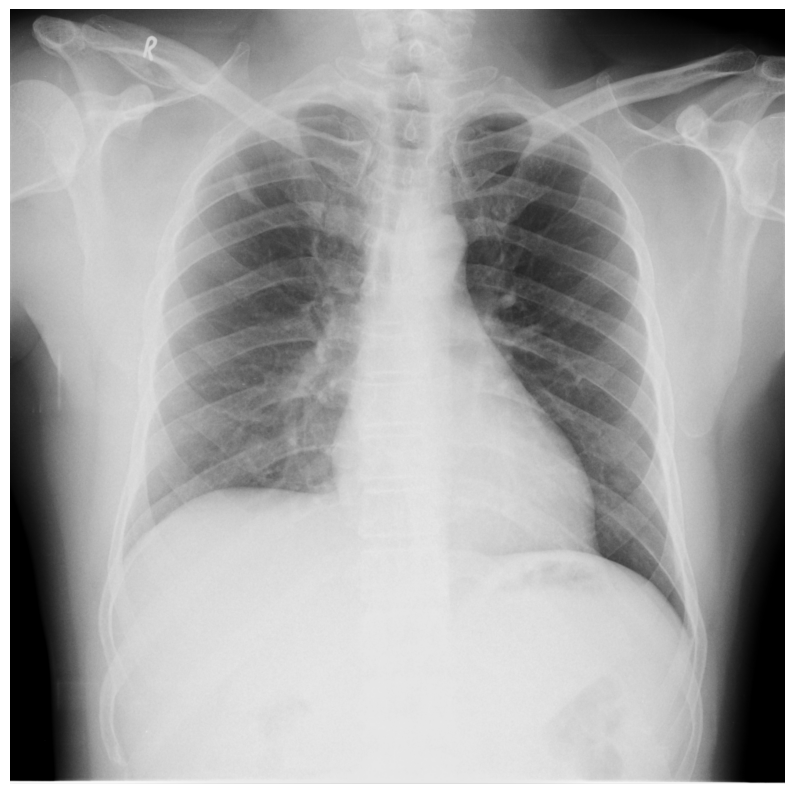

In [26]:
image_path = subset_df.filename.iloc[1] + ".png"
file_path = os.path.join("/localstorage/cxr_data/internal_data/testing/images/", image_path)
img = show_image(file_path)

In [27]:
df_results = await process_images_in_parallel(
        png_files=[file_path], # Processing the first 10 images
        prompt=PROMPT,
        concurrent_requests=40 
    )

Processing Images: 100%|██████████| 1/1 [00:05<00:00,  5.13s/it]


In [20]:
df_results

,image_path,response,status
0,/localstorage/cxr_data/internal_data/testing/i...,<|ASP|>Here is a detailed interpretation of th...,Success


In [28]:
print(df_results.response.iloc[0])

<|ASP|>asp
% ---- Devices and Interventions ----

% ---- Findings ----
finding(lung_inflation).
location(lung_inflation, bilateral).
severity(lung_inflation, normal).
characteristic(lung_inflation, adequate).

finding(trachea_position).
location(trachea_position, mediastinum).
severity(trachea_position, normal).
characteristic(trachea_position, midline).

finding(aorta_contour).
location(aorta_contour, mediastinum).
severity(aorta_contour, normal).
characteristic(aorta_contour, well_defined).

finding(cardiac_size).
location(cardiac_size, mediastinum).
severity(cardiac_size, normal).
characteristic(cardiac_size, non_enlarged).

finding(diaphragm_contour).
location(diaphragm_contour, bilateral).
severity(diaphragm_contour, normal).
characteristic(diaphragm_contour, smooth).

finding(costophrenic_sulci).
location(costophrenic_sulci, bilateral).
severity(costophrenic_sulci, normal).
characteristic(costophrenic_sulci, sharp).

finding(thoracic_spine).
location(thoracic_spine, posterior_med